In [1]:
import sys
import os
import pandas as pd

PROJECT_ROOT = os.path.abspath("..")

sys.path.append(PROJECT_ROOT)

from src.recommender import recommend_jobs

In [2]:
df = pd.read_pickle(
    "../data/processed/jobs_clean.pkl"
)

print("Dataset shape:", df.shape)

Dataset shape: (97682, 20)


In [3]:
test_candidates = [
    {
        "name": "Fresher Data Engineer",
        "role": "Data Engineering",
        "location": "Hyderabad",
        "experience": 0,
        "skills": [
            "python",
            "sql",
            "pandas"
        ]
    },

    {
        "name": "Junior AI Engineer",
        "role": "AI / ML",
        "location": "Bengaluru",
        "experience": 1,
        "skills": [
            "python",
            "machine learning",
            "numpy",
            "pandas"
        ]
    },

    {
        "name": "Junior Developer",
        "role": "Software Development",
        "location": "Hyderabad",
        "experience": 1,
        "skills": [
            "java",
            "sql",
            "javascript",
            "html",
            "css"
        ]
    },

    {
        "name": "Cloud Fresher",
        "role": "Cloud / DevOps",
        "location": "Pune",
        "experience": 0,
        "skills": [
            "aws",
            "linux",
            "python",
            "git"
        ]
    }
]

In [4]:
evaluation_results = []

for candidate in test_candidates:

    recommendations = recommend_jobs(
        df=df,
        candidate_skills=candidate["skills"],
        candidate_role=candidate["role"],
        candidate_location=candidate["location"],
        candidate_experience=candidate["experience"],
        top_n=10,
        minimum_skill_match=25
    )

    if recommendations.empty:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": 0,
            "avg_skill_match": 0,
            "avg_location_score": 0,
            "avg_experience_score": 0,
            "avg_final_score": 0
        })

    else:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": len(recommendations),
            "avg_skill_match": round(
                recommendations["skill_match"].mean(),
                2
            ),
            "avg_location_score": round(
                recommendations["location_score"].mean(),
                2
            ),
            "avg_experience_score": round(
                recommendations["experience_score"].mean(),
                2
            ),
            "avg_final_score": round(
                recommendations["final_score"].mean(),
                2
            )
        })

In [5]:
evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_df

,candidate,recommendations,avg_skill_match,avg_location_score,avg_experience_score,avg_final_score
0,Fresher Data Engineer,10,25.00,18.0,88.0,36.90
1,Junior AI Engineer,10,25.83,100.0,84.0,44.88
2,Junior Developer,10,43.75,68.0,92.0,55.82
3,Cloud Fresher,4,31.88,0.0,90.0,40.31


In [6]:
overall_metrics = {
    "Total Test Candidates": len(evaluation_df),

    "Candidates With Recommendations": (
        evaluation_df["recommendations"] > 0
    ).sum(),

    "Average Skill Match": round(
        evaluation_df["avg_skill_match"].mean(),
        2
    ),

    "Average Location Score": round(
        evaluation_df["avg_location_score"].mean(),
        2
    ),

    "Average Experience Score": round(
        evaluation_df["avg_experience_score"].mean(),
        2
    ),

    "Average Final Score": round(
        evaluation_df["avg_final_score"].mean(),
        2
    )
}

overall_metrics

{'Total Test Candidates': 4,
 'Candidates With Recommendations': np.int64(4),
 'Average Skill Match': np.float64(31.62),
 'Average Location Score': np.float64(46.5),
 'Average Experience Score': np.float64(88.5),
 'Average Final Score': np.float64(44.48)}

In [1]:
import matplotlib.pyplot as plt

metrics = [
    "avg_skill_match",
    "avg_location_score",
    "avg_experience_score",
    "avg_final_score"
]

evaluation_df[
    metrics
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Recommendation System Evaluation"
)

plt.ylabel("Score")

plt.xlabel("Test Candidate")

plt.xticks(
    range(len(evaluation_df)),
    evaluation_df["candidate"],
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.show()

NameError: name 'evaluation_df' is not defined

In [2]:
import sys
import os
import pandas as pd

PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

from src.recommender import recommend_jobs

In [3]:
df = pd.read_pickle(
    "../data/processed/jobs_clean.pkl"
)

print("Dataset shape:", df.shape)

Dataset shape: (97682, 20)


In [4]:
test_candidates = [
    {
        "name": "Fresher Data Engineer",
        "role": "Data Engineering",
        "location": "Hyderabad",
        "experience": 0,
        "skills": ["python", "sql", "pandas"]
    },
    {
        "name": "Junior AI Engineer",
        "role": "AI / ML",
        "location": "Bengaluru",
        "experience": 1,
        "skills": [
            "python",
            "machine learning",
            "numpy",
            "pandas"
        ]
    },
    {
        "name": "Junior Developer",
        "role": "Software Development",
        "location": "Hyderabad",
        "experience": 1,
        "skills": [
            "java",
            "sql",
            "javascript",
            "html",
            "css"
        ]
    },
    {
        "name": "Cloud Fresher",
        "role": "Cloud / DevOps",
        "location": "Pune",
        "experience": 0,
        "skills": [
            "aws",
            "linux",
            "python",
            "git"
        ]
    }
]

In [5]:
evaluation_results = []

for candidate in test_candidates:

    recommendations = recommend_jobs(
        df=df,
        candidate_skills=candidate["skills"],
        candidate_role=candidate["role"],
        candidate_location=candidate["location"],
        candidate_experience=candidate["experience"],
        top_n=10,
        minimum_skill_match=25
    )

    if recommendations.empty:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": 0,
            "avg_skill_match": 0,
            "avg_location_score": 0,
            "avg_experience_score": 0,
            "avg_final_score": 0
        })

    else:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": len(recommendations),
            "avg_skill_match": round(
                recommendations["skill_match"].mean(), 2
            ),
            "avg_location_score": round(
                recommendations["location_score"].mean(), 2
            ),
            "avg_experience_score": round(
                recommendations["experience_score"].mean(), 2
            ),
            "avg_final_score": round(
                recommendations["final_score"].mean(), 2
            )
        })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,candidate,recommendations,avg_skill_match,avg_location_score,avg_experience_score,avg_final_score
0,Fresher Data Engineer,10,25.00,18.0,88.0,36.90
1,Junior AI Engineer,10,25.83,100.0,84.0,44.88
2,Junior Developer,10,43.75,68.0,92.0,55.82
3,Cloud Fresher,4,31.88,0.0,90.0,40.31


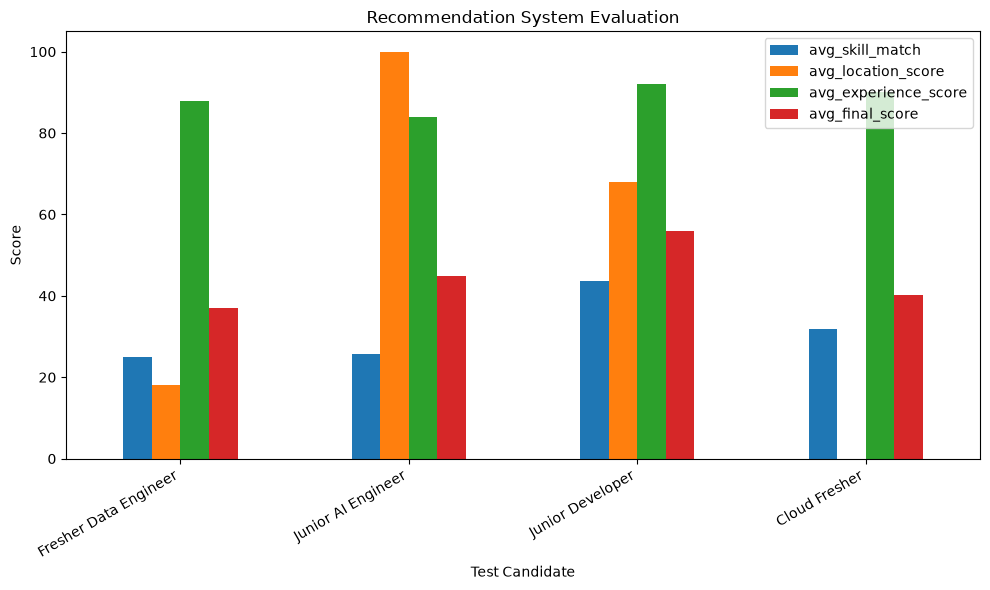

In [6]:
import matplotlib.pyplot as plt

metrics = [
    "avg_skill_match",
    "avg_location_score",
    "avg_experience_score",
    "avg_final_score"
]

evaluation_df[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Recommendation System Evaluation")
plt.ylabel("Score")
plt.xlabel("Test Candidate")

plt.xticks(
    range(len(evaluation_df)),
    evaluation_df["candidate"],
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

In [1]:
import sys
import os
import pandas as pd

PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.recommender import (
    recommend_jobs,
    location_score
)

In [2]:
print("Hyderabad → Hyderabad:",
      location_score("Hyderabad", "Hyderabad"))

print("Remote → Hyderabad:",
      location_score("Remote", "Hyderabad"))

print("Pune → Hyderabad:",
      location_score("Pune", "Hyderabad"))

print("Hyderabad, Bengaluru → Hyderabad:",
      location_score("Hyderabad, Bengaluru", "Hyderabad"))

Hyderabad → Hyderabad: 100
Remote → Hyderabad: 80
Pune → Hyderabad: 0
Hyderabad, Bengaluru → Hyderabad: 100


In [3]:
df = pd.read_pickle(
    "../data/processed/jobs_clean.pkl"
)

print(df.shape)

(97682, 20)


In [4]:
evaluation_results = []

for candidate in test_candidates:

    recommendations = recommend_jobs(
        df=df,
        candidate_skills=candidate["skills"],
        candidate_role=candidate["role"],
        candidate_location=candidate["location"],
        candidate_experience=candidate["experience"],
        top_n=10,
        minimum_skill_match=25
    )

    if recommendations.empty:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": 0,
            "avg_skill_match": 0,
            "avg_location_score": 0,
            "avg_experience_score": 0,
            "avg_final_score": 0
        })

    else:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": len(recommendations),
            "avg_skill_match": round(
                recommendations["skill_match"].mean(), 2
            ),
            "avg_location_score": round(
                recommendations["location_score"].mean(), 2
            ),
            "avg_experience_score": round(
                recommendations["experience_score"].mean(), 2
            ),
            "avg_final_score": round(
                recommendations["final_score"].mean(), 2
            )
        })

evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_df

NameError: name 'test_candidates' is not defined

In [5]:
test_candidates = [
    {
        "name": "Fresher Data Engineer",
        "role": "Data Engineering",
        "location": "Hyderabad",
        "experience": 0,
        "skills": ["python", "sql", "pandas"]
    },
    {
        "name": "Junior AI Engineer",
        "role": "AI / ML",
        "location": "Bengaluru",
        "experience": 1,
        "skills": [
            "python",
            "machine learning",
            "numpy",
            "pandas"
        ]
    },
    {
        "name": "Junior Developer",
        "role": "Software Development",
        "location": "Hyderabad",
        "experience": 1,
        "skills": [
            "java",
            "sql",
            "javascript",
            "html",
            "css"
        ]
    },
    {
        "name": "Cloud Fresher",
        "role": "Cloud / DevOps",
        "location": "Pune",
        "experience": 0,
        "skills": [
            "aws",
            "linux",
            "python",
            "git"
        ]
    }
]

print("Test candidates:", len(test_candidates))

Test candidates: 4


In [6]:
evaluation_results = []

for candidate in test_candidates:

    recommendations = recommend_jobs(
        df=df,
        candidate_skills=candidate["skills"],
        candidate_role=candidate["role"],
        candidate_location=candidate["location"],
        candidate_experience=candidate["experience"],
        top_n=10,
        minimum_skill_match=25
    )

    if recommendations.empty:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": 0,
            "avg_skill_match": 0,
            "avg_location_score": 0,
            "avg_experience_score": 0,
            "avg_final_score": 0
        })

    else:

        evaluation_results.append({
            "candidate": candidate["name"],
            "recommendations": len(recommendations),
            "avg_skill_match": round(
                recommendations["skill_match"].mean(), 2
            ),
            "avg_location_score": round(
                recommendations["location_score"].mean(), 2
            ),
            "avg_experience_score": round(
                recommendations["experience_score"].mean(), 2
            ),
            "avg_final_score": round(
                recommendations["final_score"].mean(), 2
            )
        })

evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_df

,candidate,recommendations,avg_skill_match,avg_location_score,avg_experience_score,avg_final_score
0,Fresher Data Engineer,10,25.00,18.0,88.0,36.90
1,Junior AI Engineer,10,25.83,100.0,84.0,44.88
2,Junior Developer,10,43.75,68.0,92.0,55.82
3,Cloud Fresher,4,31.88,0.0,90.0,40.31


In [7]:
print(
    "Location scores:",
    sorted(
        df["location"].dropna().unique()
    )[:10]
)

Location scores: ['Abohar', 'Abu Road', 'Achalpur', 'Achampet', 'Adampur, Punjab', 'Adilabad', 'Adoni', 'Adoor', 'Agartala', 'Agartala, Anantapur, Kurnool']


In [8]:
print(
    "Evaluation location scores:",
    evaluation_df["avg_location_score"].tolist()
)

Evaluation location scores: [18.0, 100.0, 68.0, 0.0]


In [9]:
test = recommend_jobs(
    df=df,
    candidate_skills=["python", "sql", "pandas"],
    candidate_role="Data Engineering",
    candidate_location="Hyderabad",
    candidate_experience=0,
    top_n=10,
    minimum_skill_match=25
)

test[
    [
        "title",
        "location",
        "location_score",
        "skill_match",
        "experience_score",
        "final_score"
    ]
]

,title,location,location_score,skill_match,experience_score,final_score
45144,Data Engineer - Snowflake,Hyderabad,100,25.0,80,43.5
8653,Big Data Engineer,Remote,80,25.0,80,41.5
10338,Trainee/Junior Data Engineer,Noida,0,25.0,100,37.5
33882,Intern - Data Engineering,Mumbai,0,25.0,100,37.5
52712,Trainee Data Engineer,Gurugram,0,25.0,100,37.5
80565,Business Technology Solutions Associate_ Cloud...,Pune,0,25.0,100,37.5
4078,Data Engineer|L1 Support|Noida,"Noida, Mumbai",0,25.0,80,33.5
22795,Data Engineer For Private Bank One Data Platfo...,Pune,0,25.0,80,33.5
22901,Fixed Income Data Engineer,Pune,0,25.0,80,33.5
71725,Senior Data Engineer,Thiruvananthapuram,0,25.0,80,33.5


In [10]:
test = recommend_jobs(
    df=df,
    candidate_skills=["python", "sql", "pandas"],
    candidate_role="Data Engineering",
    candidate_location="Hyderabad",
    candidate_experience=0,
    top_n=10,
    minimum_skill_match=25
)

test[
    [
        "title",
        "location",
        "location_score",
        "skill_match",
        "experience_score",
        "final_score"
    ]
]

,title,location,location_score,skill_match,experience_score,final_score
45144,Data Engineer - Snowflake,Hyderabad,100,25.0,80,43.5
8653,Big Data Engineer,Remote,80,25.0,80,41.5
10338,Trainee/Junior Data Engineer,Noida,0,25.0,100,37.5
33882,Intern - Data Engineering,Mumbai,0,25.0,100,37.5
52712,Trainee Data Engineer,Gurugram,0,25.0,100,37.5
80565,Business Technology Solutions Associate_ Cloud...,Pune,0,25.0,100,37.5
4078,Data Engineer|L1 Support|Noida,"Noida, Mumbai",0,25.0,80,33.5
22795,Data Engineer For Private Bank One Data Platfo...,Pune,0,25.0,80,33.5
22901,Fixed Income Data Engineer,Pune,0,25.0,80,33.5
71725,Senior Data Engineer,Thiruvananthapuram,0,25.0,80,33.5


In [11]:
test["location_score"].value_counts()

location_score
0      8
100    1
80     1
Name: count, dtype: int64

# Recommendation System Evaluation Results

The recommendation engine was evaluated using four simulated candidate profiles representing different technology career paths.

The evaluation measures recommendation compatibility using:

- Skill Match
- Location Compatibility
- Experience Compatibility
- Final Recommendation Score
- Number of Recommendations

These metrics evaluate ranking and compatibility rather than prediction accuracy, because the system is a recommendation engine and does not have a ground-truth hiring outcome.

## Evaluation Summary

| Candidate Profile | Recommendations | Avg Skill Match | Avg Location Score | Avg Experience Score | Avg Final Score |
|---|---:|---:|---:|---:|---:|
| Fresher Data Engineer | 10 | 25.00% | 18.00% | 88.00% | 36.90% |
| Junior AI Engineer | 10 | 25.83% | 100.00% | 84.00% | 44.88% |
| Junior Developer | 10 | 43.75% | 68.00% | 92.00% | 55.82% |
| Cloud Fresher | 4 | 31.88% | 0.00% | 90.00% | 40.31% |

## Observations

1. The Junior Developer profile achieved the highest average final recommendation score of 55.82%.

2. The Junior Developer profile also achieved the highest average skill match of 43.75%.

3. The Junior AI Engineer profile achieved 100% average location compatibility for the tested Bengaluru preference.

4. The Cloud Fresher profile returned four recommendations rather than ten, demonstrating that the system does not force weak matches when fewer opportunities satisfy the configured skill-match threshold.

5. The results demonstrate that the recommendation engine considers multiple dimensions rather than relying only on job-title similarity.